In [ ]:
# python 3.10.8

import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
from util.ssim import *
from util.utils import *

In [ ]:
PA_from_base, df_images, greyscaleImages = load_images()

In [ ]:
df = pd.read_parquet("image_quality_metrics_analysis.parquet", engine="fastparquet")

In [ ]:
# Reconstruct variables from df
(
    drop_fractions,
    avg_scores_drop,
    mean_taus_drop,
    mean_ps_drop,
    scores_drop,
    sensitivities_drop,
) = get_distortion_vars(df, "drop")

(
    variance_levels,
    avg_scores_noise,
    mean_taus_noise,
    mean_ps_noise,
    scores_noise,
    sensitivities_noise,
) = get_distortion_vars(df, "noise")

(
    blur_levels,
    avg_scores_blur,
    mean_taus_blur,
    mean_ps_blur,
    scores_blur,
    sensitivities_blur,
) = get_distortion_vars(df, "blur")

In [ ]:
from scipy.stats import linregress, wilcoxon


def compute_sensitivity_metrics(avg_scores, scores, levels):
    results = {}
    for metric, values in avg_scores.items():
        if metric in {'mse', 'psnr', 'snr'}:
            continue
        # Avg. score drop per step
        step_diffs = np.abs(np.diff(values))
        avg_drop = np.mean(step_diffs)
        max_drop = np.max(step_diffs)

        # Linear slope
        slope, _, r_value, _, _ = linregress(levels, values)

        # Adjacent-level sensitivity rate (Wilcoxon signed-rank test)
        significant_changes = 0
        for i in range(len(levels) - 1):
            scores1 = scores[metric][i]
            scores2 = scores[metric][i + 1]
            try:
                stat, p = wilcoxon(scores1, scores2)
                if p < 0.05:
                    significant_changes += 1
            except ValueError:
                continue  # skip cases with insufficient data

        sensitivity_rate = significant_changes / (len(levels) - 1)
        print(metric)
        results[metric] = {
            "Avg. Drop": avg_drop,
            "Max Drop": max_drop,
            "Slope": slope,
            "Adj-Level Sensitivity Rate": sensitivity_rate
        }
    return results

sensitivity_table = compute_sensitivity_metrics(avg_scores_drop, scores_drop, drop_fractions)

df1 = pd.DataFrame(sensitivity_table).T
print(df)

sensitivity_table = compute_sensitivity_metrics(avg_scores_noise, scores_noise, variance_levels)

df2 = pd.DataFrame(sensitivity_table).T
print(df)

sensitivity_table = compute_sensitivity_metrics(avg_scores_blur, scores_blur, blur_levels)

df3 = pd.DataFrame(sensitivity_table).T
print(df)

ssim
wssim
msssim
s3im
ws3im
mss3im
    distortion_type metric_variant  distortion_level  avg_score  mean_tau  \
0              drop           ssim          0.000000   1.000000      -1.0   
1              drop           ssim          0.052632   0.988068      -1.0   
2              drop           ssim          0.105263   0.977447      -1.0   
3              drop           ssim          0.157895   0.968024      -1.0   
4              drop           ssim          0.210526   0.958821      -1.0   
..              ...            ...               ...        ...       ...   
598              pa            snr          6.000000   7.679039       NaN   
599              pa            snr          5.000000   2.187754       NaN   
600              pa            snr          4.000000  -1.316296       NaN   
601              pa            snr          3.000000  -4.184164       NaN   
602              pa            snr          2.000000  -8.140070       NaN   

           mean_p                      

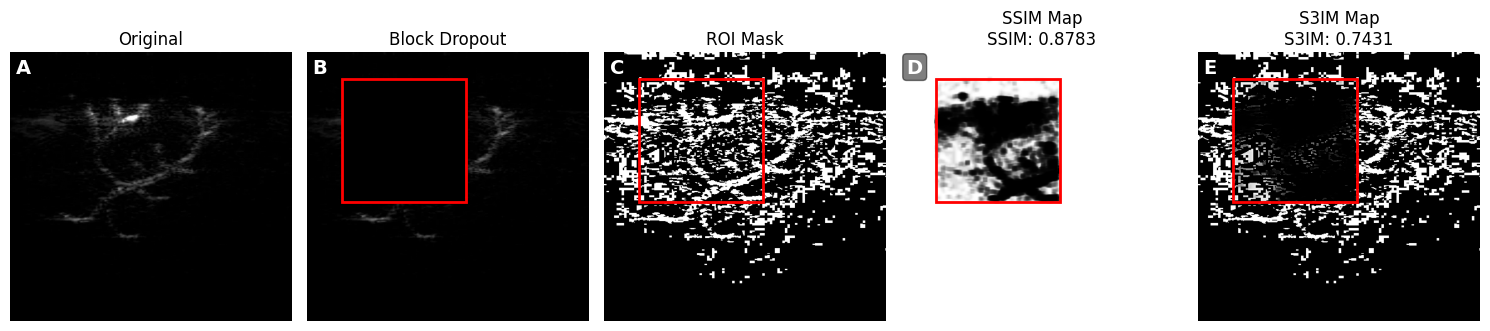

In [ ]:
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

# === Load and preprocess ===
with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)

# === Apply dropout ===
block_dropped_mask = calculate_single_mask(original_img)
block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# === Compute SSIM and S3IM ===
SSIM_score, ssim_map = structural_similarity(
    original_img, block_dropped_img, win_size=7, full=True, data_range=1.0
)
S3IM_score, s3im_mask, s3im_map = s3im(original_img, block_dropped_img, window_size=7)

# === Prepare visualization ===
titles = ["Original", "Block Dropout", "ROI Mask", "SSIM Map", "S3IM Map"]
images = [original_img, block_dropped_img, s3im_mask, ssim_map, s3im_map]
labels = ['A', 'B', 'C', 'D', 'E']  # per-image labels

# === Plot ===
fig, axes = plt.subplots(1, 5, figsize=(15, 8))
axes = axes.flatten()

for idx, (ax, title, img, label) in enumerate(zip(axes, titles, images, labels)):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')

    # Add ROI rectangle everywhere except the Original
    if idx != 0:
        rect = Rectangle((x, y), size, size, linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)

    # Put (a)–(e) inside each subplot (top-left)
    ax.text(
        0.02, 0.98, label,
        transform=ax.transAxes,
        color='white',
        fontsize=14,
        fontweight='bold',
        va='top', ha='left',
        bbox=dict(facecolor='black', alpha=0.5, boxstyle='round,pad=0.2')
    )

    # Titles (with metrics where relevant)
    if idx == 3:
        ax.set_title(f"{title}\nSSIM: {SSIM_score:.4f}", fontsize=12)
    elif title == "S3IM Map":
        ax.set_title(f"{title}\nS3IM: {S3IM_score:.4f}", fontsize=12)
    else:
        ax.set_title(title, fontsize=12)

# Hide any unused axes (safety)
if len(images) < len(axes):
    for i in range(len(images), len(axes)):
        axes[i].axis("off")

plt.tight_layout()
plt.show()


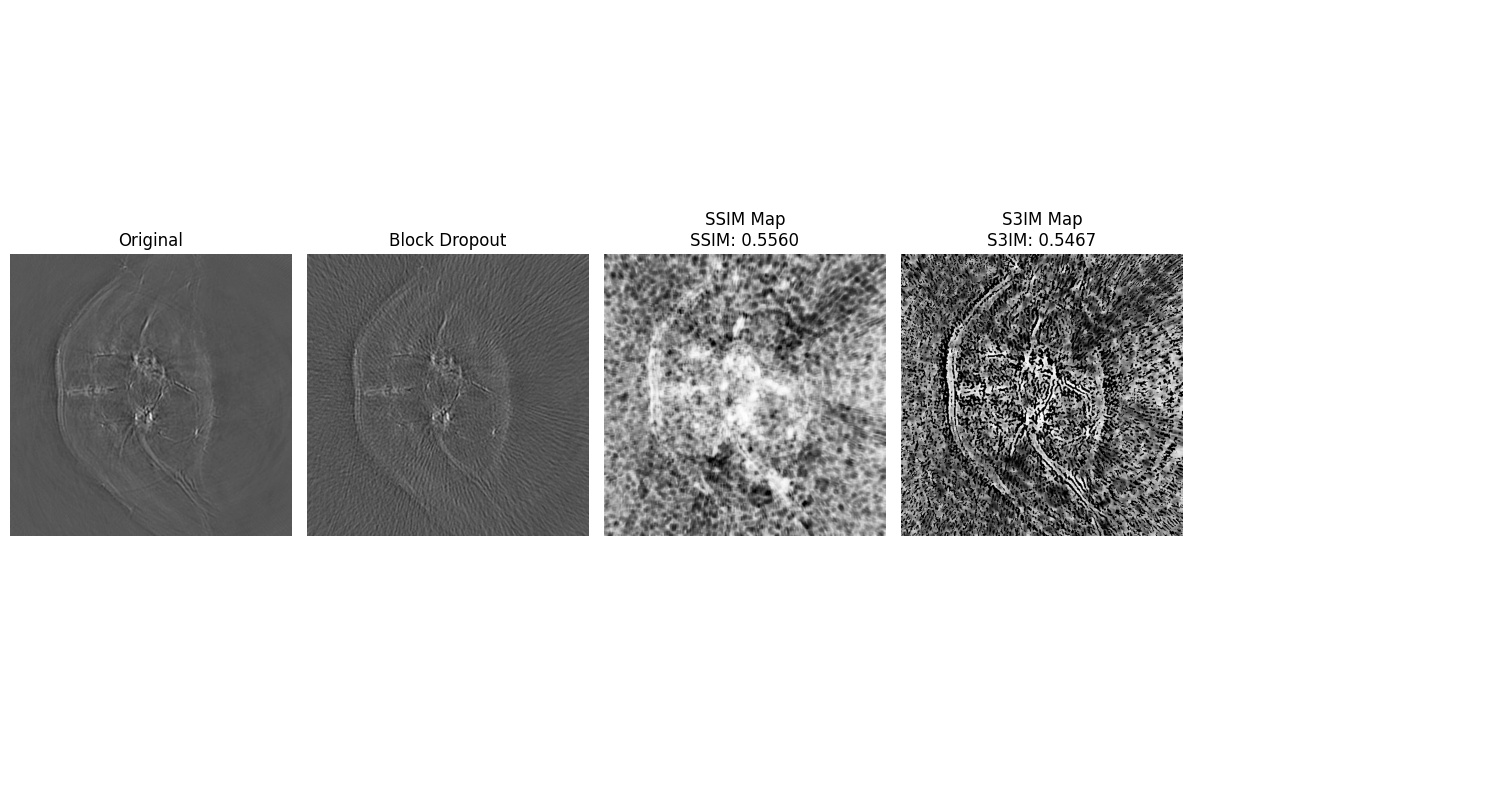

In [ ]:
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)

# Apply dropout
block_dropped_mask = calculate_single_mask(original_img)
block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(original_img, block_dropped_img, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(original_img, block_dropped_img, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "ROI Mask", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    original_img, 
    block_dropped_img, 
    s3im_mask,
    ssim_map, 
    s3im_map
]

from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_2213/image_192_full.webp") as img:
    ref_img = img.convert('L')
    ref_img = img_as_float(ref_img)
    # mask2 = calculate_single_mask(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_2213/image_192_128.webp") as img:
    ref_img2 = img.convert('L')
    ref_img2 = img_as_float(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_3215/SWFD_semicircle_sc_BP_slice0046.webp") as img:
    ref_img3 = img.convert('L')
    ref_img3 = img_as_float(ref_img3)
    # mask2 = calculate_single_mask(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_3215/SWFD_semicircle_sc,ss32_BP_slice0046.webp") as img:
    ref_img4 = img.convert('L')
    ref_img4 = img_as_float(ref_img4)
# Apply dropout
# block_dropped_mask = calculate_single_mask(original_img)
# block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(ref_img, ref_img2, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(ref_img, ref_img2, window_size=7)

SSIM_score2, ssim_map2 = structural_similarity(ref_img3, ref_img4, win_size=7, full=True, data_range=1.0)
S3IM_score2, s3im_mask2, s3im_map2 = s3im(ref_img3, ref_img4, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    ref_img,
    ref_img2, 
    ssim_map, 
    s3im_map
]

# Plot in 2 rows (3 cols max)
fig, axes = plt.subplots(1, 5, figsize=(15, 8))
axes = axes.flatten()

for idx, (ax, title, img) in enumerate(zip(axes, titles, images)):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
    if title =="SSIM Map":
        ax.set_title(
            f"""{title}
SSIM: {SSIM_score:.4f}""",
            fontsize=12
        )
    elif title == "S3IM Map":
        ax.set_title(
            f"""{title}
S3IM: {S3IM_score:.4f}""",
            fontsize=12
        )
    else:
        ax.set_title(title, fontsize=12)

# Hide any extra subplot (if 6th is unused)
if len(images) < len(axes):
    for i in range(len(images), len(axes)):
        axes[i].axis("off")

plt.tight_layout()
plt.show()


C:\Users\SemKj\AppData\Local\Temp\ipykernel_2416\3468866717.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


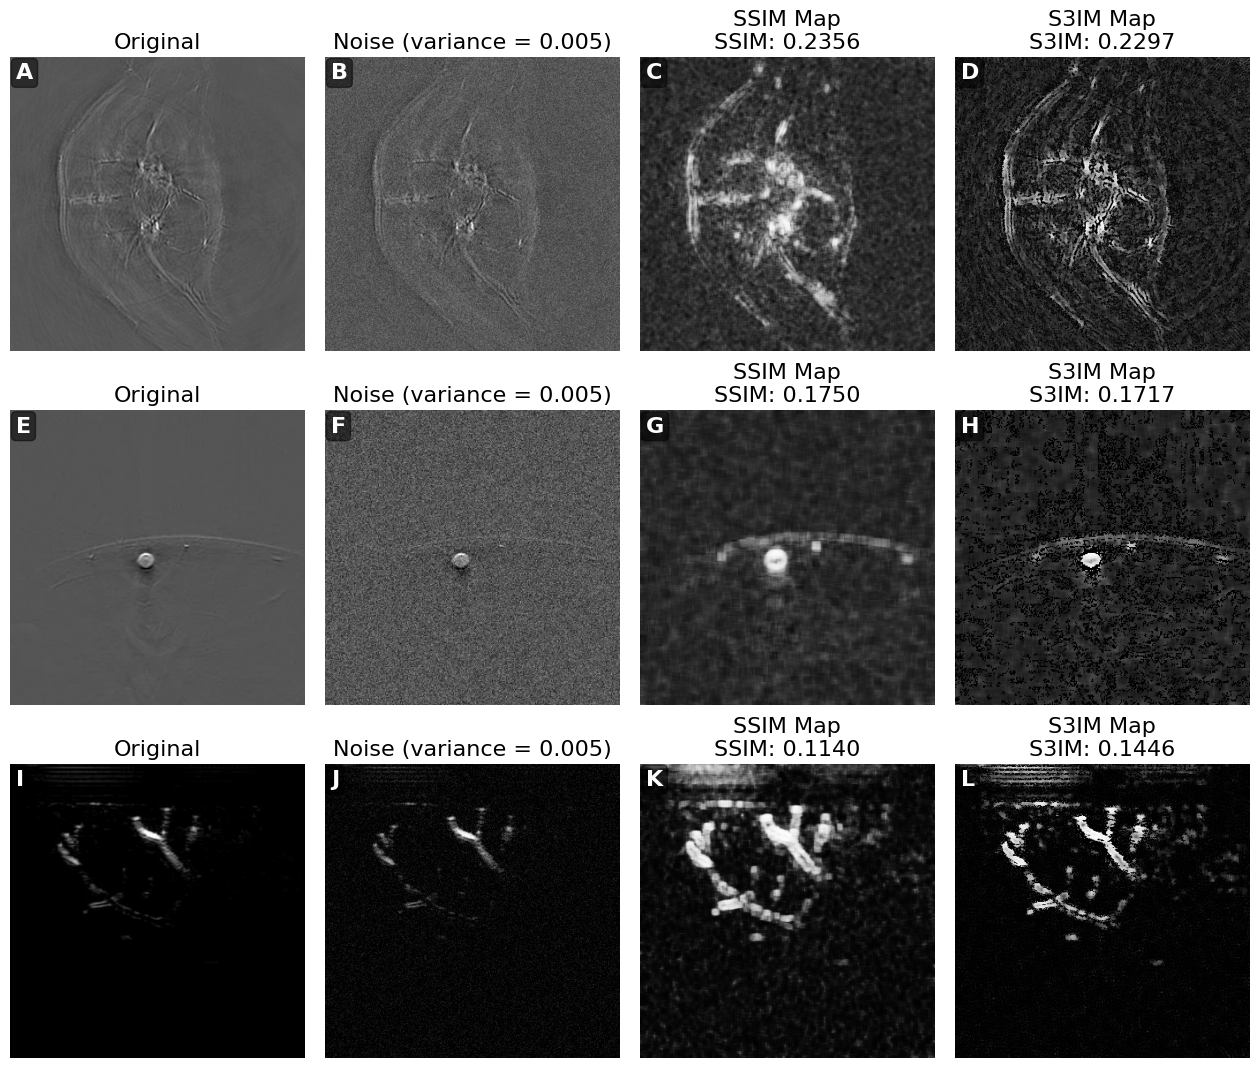

In [ ]:
from matplotlib import pyplot as plt
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float, random_noise

# === Load and preprocess images ===
with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_2213/image_192_full.webp") as img:
    ref_img = img.convert('L')
    ref_img = img_as_float(ref_img)

ref_img2 = random_noise(ref_img, mode='gaussian', var=0.005, clip=True, rng=42)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_3215/SWFD_semicircle_sc_BP_slice0046.webp") as img:
    ref_img3 = img.convert('L')
    ref_img3 = img_as_float(ref_img3)

ref_img4 = random_noise(ref_img3, mode='gaussian', var=0.005, clip=True, rng=42)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5002/KWave_Rf_102622_011023 PA_GT.webp") as img:
    ref_img5 = img.convert('L')
    ref_img5 = img_as_float(ref_img5)

ref_img6 = random_noise(ref_img5, mode='gaussian', var=0.005, clip=True, rng=42)

# === Compute SSIM and S3IM ===
SSIM_score, ssim_map = structural_similarity(ref_img, ref_img2, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(ref_img, ref_img2, window_size=7)

SSIM_score2, ssim_map2 = structural_similarity(ref_img3, ref_img4, win_size=7, full=True, data_range=1.0)
S3IM_score2, s3im_mask2, s3im_map2 = s3im(ref_img3, ref_img4, window_size=7)

SSIM_score3, ssim_map3 = structural_similarity(ref_img5, ref_img6, win_size=7, full=True, data_range=1.0)
S3IM_score3, s3im_mask3, s3im_map3 = s3im(ref_img5, ref_img6, window_size=7)

# === Prepare visualization ===
titles = ["Original", "Noise (variance = 0.005)", "SSIM Map", "S3IM Map"]

images1 = [ref_img, ref_img2, ssim_map, s3im_map]
scores1 = [None, None, SSIM_score, S3IM_score]

images2 = [ref_img3, ref_img4, ssim_map2, s3im_map2]
scores2 = [None, None, SSIM_score2, S3IM_score2]

images3 = [ref_img5, ref_img6, ssim_map3, s3im_map3]
scores3 = [None, None, SSIM_score3, S3IM_score3]

# Labels (a)–(l)
labels = [f"{chr(97+i)}".upper() for i in range(12)]  # ['(a)', '(b)', ..., '(l)']

# === Create subplot grid: 3 rows × 4 cols ===
fig, axes = plt.subplots(3, 4, figsize=(18, 13), gridspec_kw={'wspace': -0.3, 'hspace': 0.2})


# Plot rows with labels a–d, e–h, i–l
plot_row(axes[0], titles, images1, scores1, labels[0:4])
plot_row(axes[1], titles, images2, scores2, labels[4:8])
plot_row(axes[2], titles, images3, scores3, labels[8:12])

plt.tight_layout()
plt.show()


In [ ]:
with PIL_Image.open("Ground_Truth.tif") as img:
    GT = img.convert('L')
    GT = img_as_float(GT)

with PIL_Image.open("Experiment_Water.tif") as img:
    WATER = img.convert('L')
    WATER = img_as_float(WATER)

with PIL_Image.open("Experiment_Phantom.tif") as img:
    PHANTOM = img.convert('L')
    PHANTOM = img_as_float(PHANTOM)

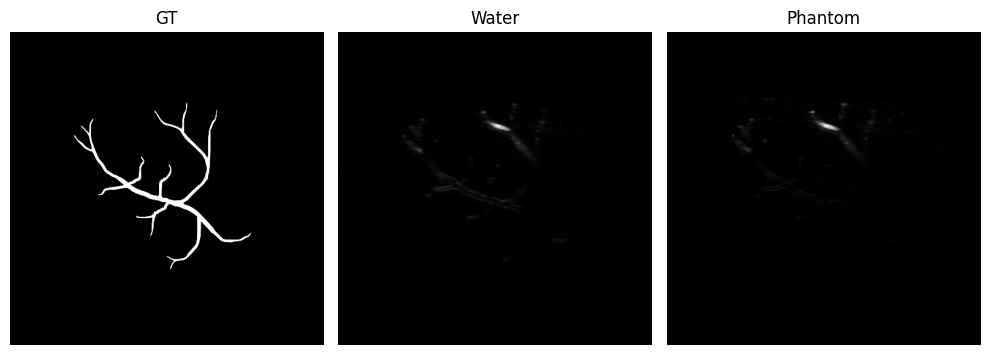

In [ ]:
from skimage.io import imread
from skimage.util import img_as_float

GT = img_as_float(imread("Ground_Truth.tif"))
WATER = img_as_float(imread("Experiment_Water.tif"))
PHANTOM = img_as_float(imread("Experiment_Phantom.tif"))

    
fig, axes = plt.subplots(1, 3, figsize=(10, 5))

axes[0].imshow(GT, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("GT")
axes[0].axis('off')

axes[1].imshow(WATER, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("Water")
axes[1].axis('off')

axes[2].imshow(PHANTOM, cmap='gray', vmin=0, vmax=1)
axes[2].set_title("Phantom")
axes[2].axis('off')

plt.tight_layout()
plt.show()


res_phantom = mss3im(GT, PHANTOM)
maps_phantom = res_phantom[2]
res_water = mss3im(GT, WATER)
maps_water = res_water[2]

# print('phantom')
# print(res_phantom[0])
# visualize_maps(maps_phantom)
# visualize_maps([res_phantom[1]])

# print('water')
# print(res_water[0])
# visualize_maps(maps_water)
# visualize_maps([res_water[1]])


# s3im_score, _, _ = s3im(GT, WATER, SSIM_variant=structural_similarity)

# print(s3im_score)

# structural_similarity(GT, PHANTOM,win_size=7, full=True, data_range=1.0)
# structural_similarity(GT, WATER,win_size=7, full=True, data_range=1.0)

# mss3im(GT, WATER, roi=False)[0]
# mss3im(GT, PHANTOM, roi=False)[0]

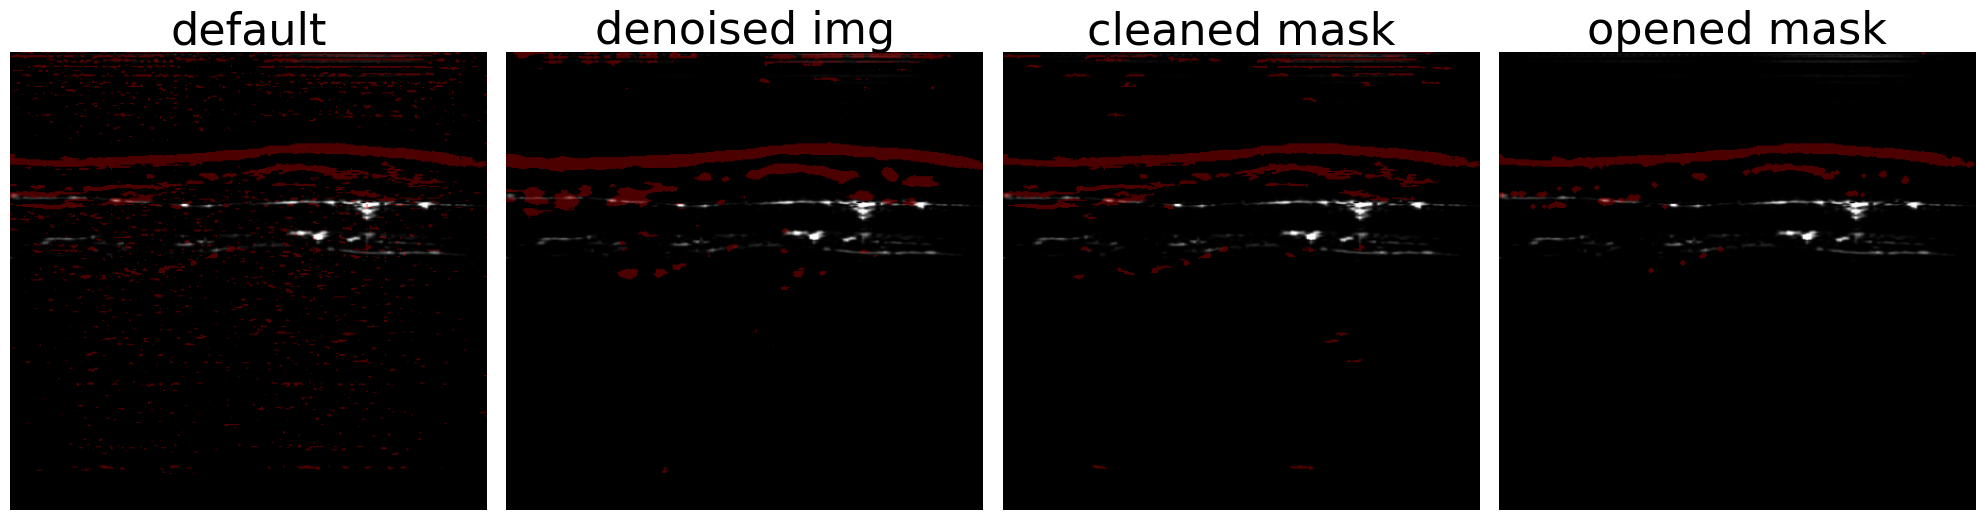

In [ ]:
from scipy.ndimage import median_filter
from skimage.morphology import binary_opening, disk, remove_small_objects

default_mask = calculate_combined_mask(greyscaleImages[5], greyscaleImages[5], sensitivity=0.45)

# denoised img
img_denoised = median_filter(greyscaleImages[5], size=12)
denoised_mask = calculate_combined_mask(img_denoised, img_denoised, sensitivity=0.48)

mask_clean = remove_small_objects(default_mask, min_size=24)

mask_opened = binary_opening(default_mask, disk(2))

masks = [default_mask, denoised_mask, mask_clean, mask_opened]
# images = [greyscaleImages[0], greyscaleImages[0], greyscaleImages[0], greyscaleImages[0]]
titles = ["default", "denoised img", "cleaned mask", "opened mask"]

visualize_multiple_masks(greyscaleImages[0], masks, titles, 0.3)

In [ ]:
# [VARIED SPLIT CONTENTS]
#   [Mouse Phantom]
#     22xx Mice x10 IN VIVO
#     23xx Phantom - 3 Circles x4 PHANTOM
#   [OADAT]
#     32xx SWFD_sc SEMICIRCLE x10 IN VIVO
#     33xx SWFD_ms MULTISEGMENT x10 IN VIVO
#   [ACOUSTICX]
#     50xx KWave x2 PHANTOM
#     50xx Doransso Phantom x1 PHANTOM
#     50xx BMPI Phantom x1 PHANTOM 
#     50xx BV Phantom x1 PHANTOM
#     51xx Wrist x1 IN VIVO
#     51xx Radial x1 IN VIVO
#     51xx Finger x1 IN VIVO
#   [VISUALSONICS]
#     6xxx Bladder x1 IN VIVO
#     6xxx Brain x1 IN VIVO
#     6xxx Hindlimb x1 IN VIVO
#     6xxx Kidney x1 IN VIVO
#     6xxx Liver x1 IN VIVO

oimg1 = PA_from_base["Invivo__BloodvesselDepth_Rf_061821_180645"]["PA1"]
oimg2 = PA_from_base["Invivo__BloodvesselDepth_Rf_061821_180645"]["PA7"]
# calculate_and_visualise_masks(img1, img2)

oimg3 = PA_from_base["Invivo__BloodvesselDepth_Rf_061821_180645"]["PA2"]
# calculate_and_visualise_masks(img1, img2)

#   [Mouse Phantom]
#     22xx Mice x10 IN VIVO
#     23xx Phantom - 3 Circles x4 PHANTOM
print("[Mouse Phantom]")
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_2201/image_113_full.webp") as img:
        img1 = img.convert('L')
        img1 = img_as_float(img1)
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_2201/image_113_256.webp") as img:
        img2 = img.convert('L')
        img2 = img_as_float(img2)
# calculate_and_visualise_masks(img1, img2)

with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_2201/image_113_16.webp") as img:
        img3 = img.convert('L')
        img3 = img_as_float(img2)
# calculate_and_visualise_masks(img1, img2)

#   [OADAT]
#     32xx SWFD_sc SEMICIRCLE x10 IN VIVO
#     33xx SWFD_ms MULTISEGMENT x10 IN VIVO
print("[OADAT]")
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_3203/SWFD_semicircle_sc_BP_slice0090.webp") as img:
        aimg1 = img.convert('L')
        aimg1 = img_as_float(aimg1)
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_3203/SWFD_semicircle_sc,lv128_BP_slice0090.webp") as img:
        aimg2 = img.convert('L')
        aimg2 = img_as_float(aimg2)
# calculate_and_visualise_masks(img1, img2)

with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_3203/SWFD_semicircle_sc,ss32_BP_slice0090.webp") as img:
        aimg3 = img.convert('L')
        aimg3 = img_as_float(aimg2)
# calculate_and_visualise_masks(img1, img2)


#   [ACOUSTICX]
#     50xx KWave x2 PHANTOM
#     50xx Doransso Phantom x1 PHANTOM
#     50xx BMPI Phantom x1 PHANTOM 
#     50xx BV Phantom x1 PHANTOM
#     51xx Wrist x1 IN VIVO
#     51xx Radial x1 IN VIVO
#     51xx Finger x1 IN VIVO
print("[ACOUSTICX]")
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
        bimg1 = img.convert('L')
        bimg1 = img_as_float(bimg1)
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA7.webp") as img:
        bimg2 = img.convert('L')
        bimg2 = img_as_float(bimg2)
# calculate_and_visualise_masks(img1, img2)

with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA2.webp") as img:
        bimg3 = img.convert('L')
        bimg3 = img_as_float(bimg2)
# calculate_and_visualise_masks(img1, img2)

#   [VISUALSONICS]
#     6xxx Bladder x1 IN VIVO
#     6xxx Brain x1 IN VIVO
#     6xxx Hindlimb x1 IN VIVO
#     6xxx Kidney x1 IN VIVO
#     6xxx Liver x1 IN VIVO
print("[VISUALSONICS]")
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_6003/Hindlimb 49-80.webp") as img:
        cimg1 = img.convert('L')
        cimg1.thumbnail((512, 512), resample=PIL_Image.BILINEAR)
        cimg1 = img_as_float(cimg1)
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_6003/Hindlimb 53-80.webp") as img:
        cimg2 = img.convert('L')
        cimg2.thumbnail((512, 512), resample=PIL_Image.BILINEAR)
        cimg2 = img_as_float(cimg2)
# calculate_and_visualise_masks(img1, img2)

with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_6003/Hindlimb 59-80.webp") as img:
        cimg3 = img.convert('L')
        cimg3.thumbnail((512, 512), resample=PIL_Image.BILINEAR)
        cimg3 = img_as_float(cimg2)
# calculate_and_visualise_masks(img1, img2)

rows = [
    ("Invivo Bloodvessel", [
        ('High quality', oimg1, oimg2),   # HIGH
    ]),

    ("Mouse Phantom", [
        ('High quality',img1, img2),   # HIGH
    ]),

    ("OADAT", [
        ('High quality',aimg1, aimg2),   # HIGH
    ]),

    ("AcousticX", [
        ('High quality',bimg1, bimg2),   # HIGH
    ]),

    ("VisualSonics", [
        ('High quality',cimg1, cimg2),   # HIGH
    ]),
]


[Mouse Phantom]
[OADAT]
[ACOUSTICX]
[VISUALSONICS]


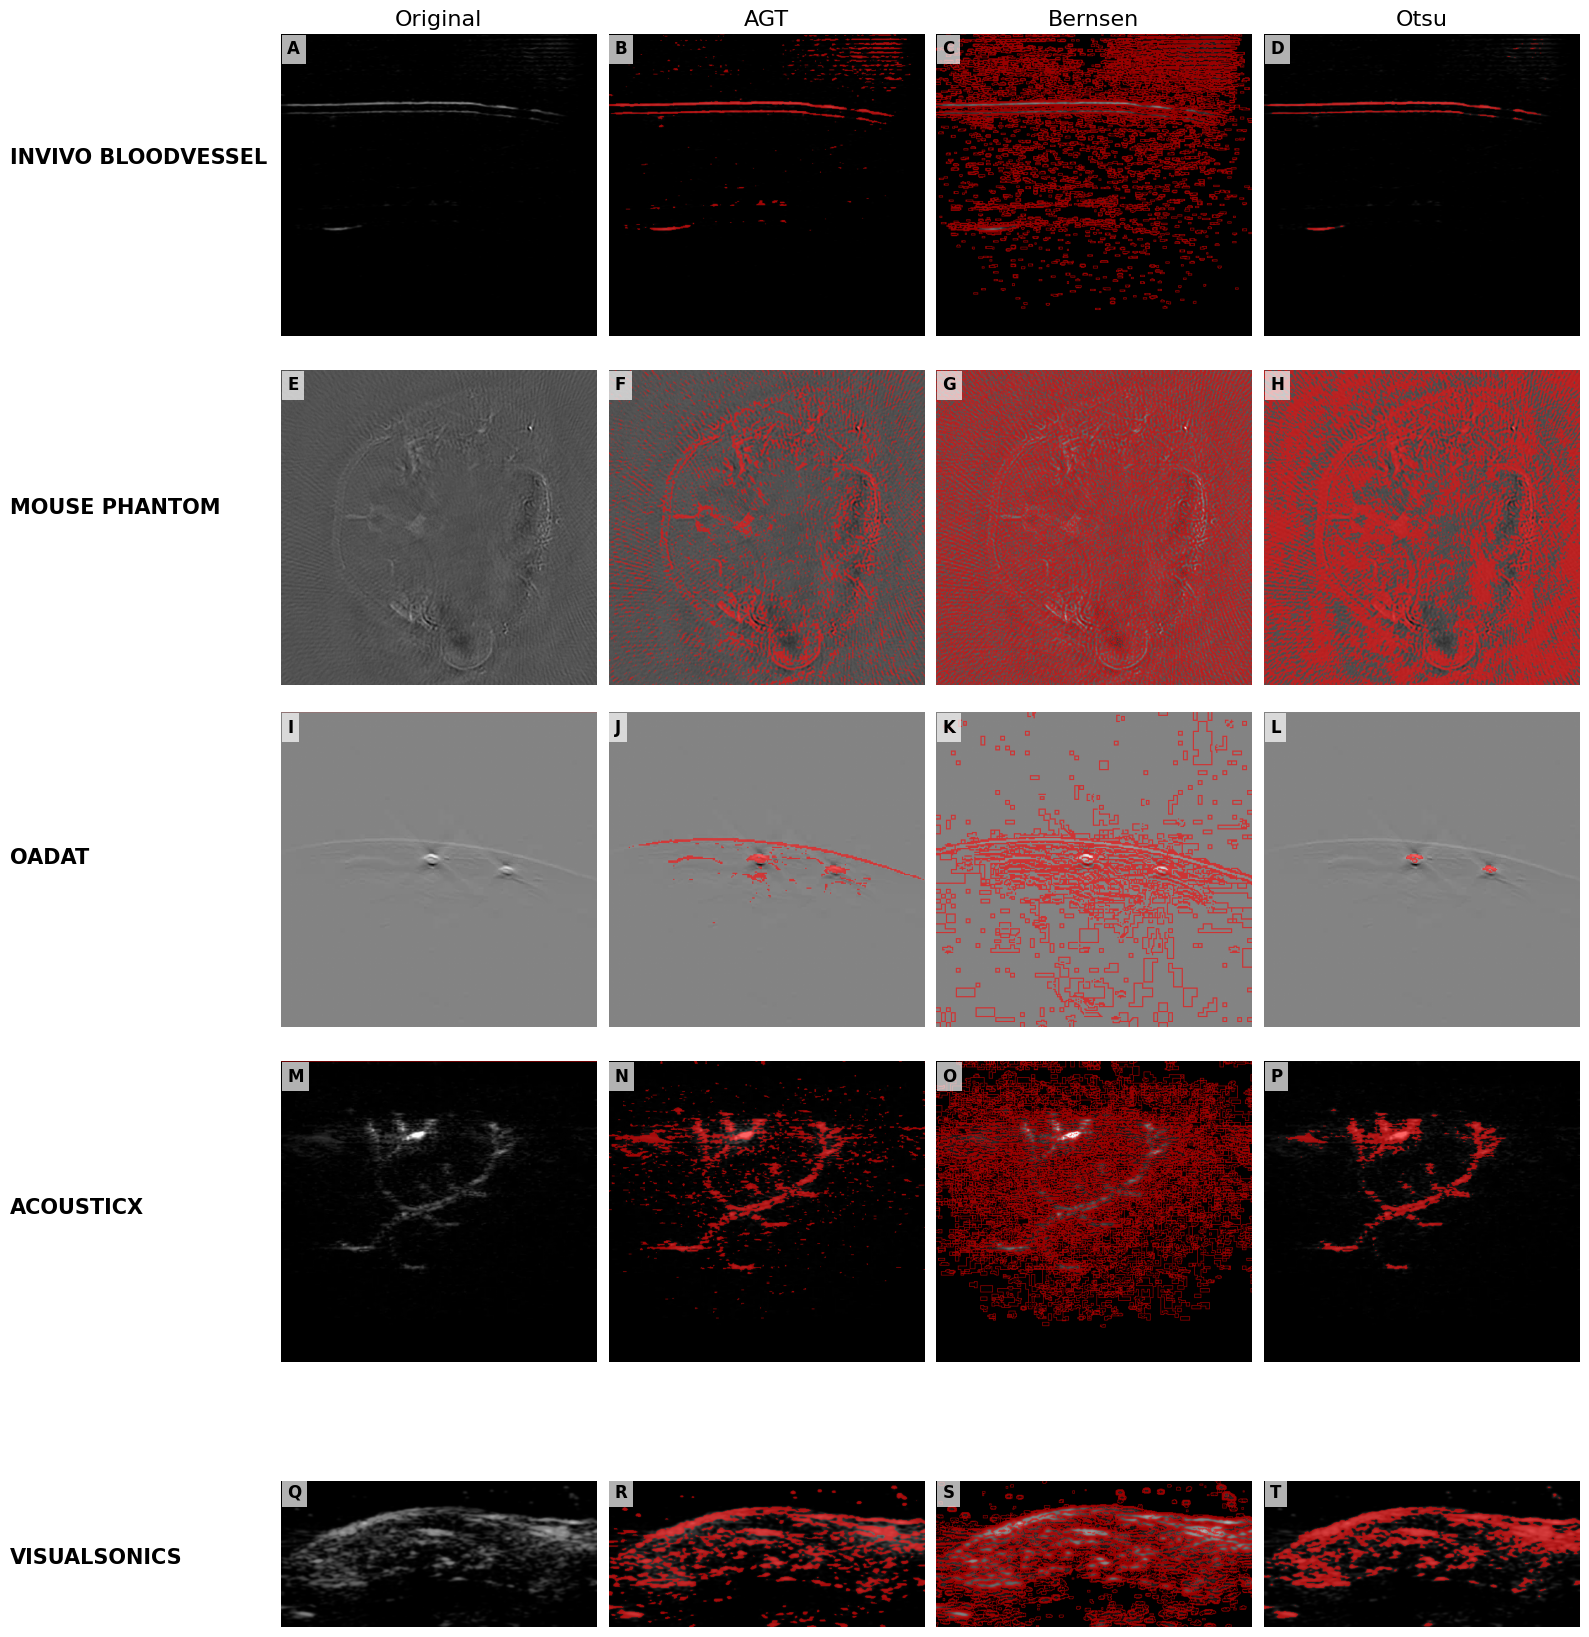

In [ ]:



visualize_all_mask_rows(rows)


c:\Users\SemKj\Downloads\s3im\s3im\lib\site-packages\skimage\metrics\simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


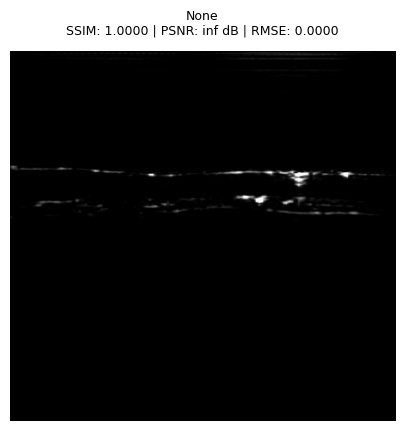

In [ ]:
original_img = greyscaleImages[0]
distorted_img = random_noise(original_img, mode='gaussian', var=0.2, clip=True, rng=42)

mask = calculate_combined_mask(original_img, original_img)
locally_distorted_img = distorted_img * mask + original_img * (1 - mask)

distorted_img = random_noise(original_img, mode='gaussian', var=0.01, clip=True, rng=42)
outside_distorted_img = distorted_img * (1 - mask) + original_img * mask



noisy_img = gaussian_filter(original_img, sigma=6)
locally_blur_img = original_img * (1 - mask) + noisy_img * mask
outside_blur_img = original_img * mask + noisy_img * (1-mask)


dropped = drop_pixels(original_img, 0.8)

def show_image_with_ssim(img, distorted_img, title, data_range=1.0):
    ssim_val = structural_similarity(distorted_img, img, data_range=data_range)
    rmse_score = mean_squared_error(distorted_img, img)**0.5
    psnr_score = peak_signal_noise_ratio(distorted_img, img, data_range=1.0)
    plt.imshow(distorted_img, cmap='gray')
    plt.axis('off')
    plt.title(f"{title}\nSSIM: {ssim_val:.4f} | PSNR: {psnr_score:.2f} dB | RMSE: {rmse_score:.4f}", fontsize=9, pad=12)
    plt.show()

show_image_with_ssim(original_img, original_img, "None")
# show_image_with_ssim(original_img, locally_distorted_img, "Noise")
# show_image_with_ssim(original_img, outside_distorted_img, "Noise")
# show_image_with_ssim(original_img, locally_blur_img, "Blur")
# show_image_with_ssim(original_img, outside_blur_img, "Blur")
# show_image_with_ssim(original_img, dropped, "Dropout")

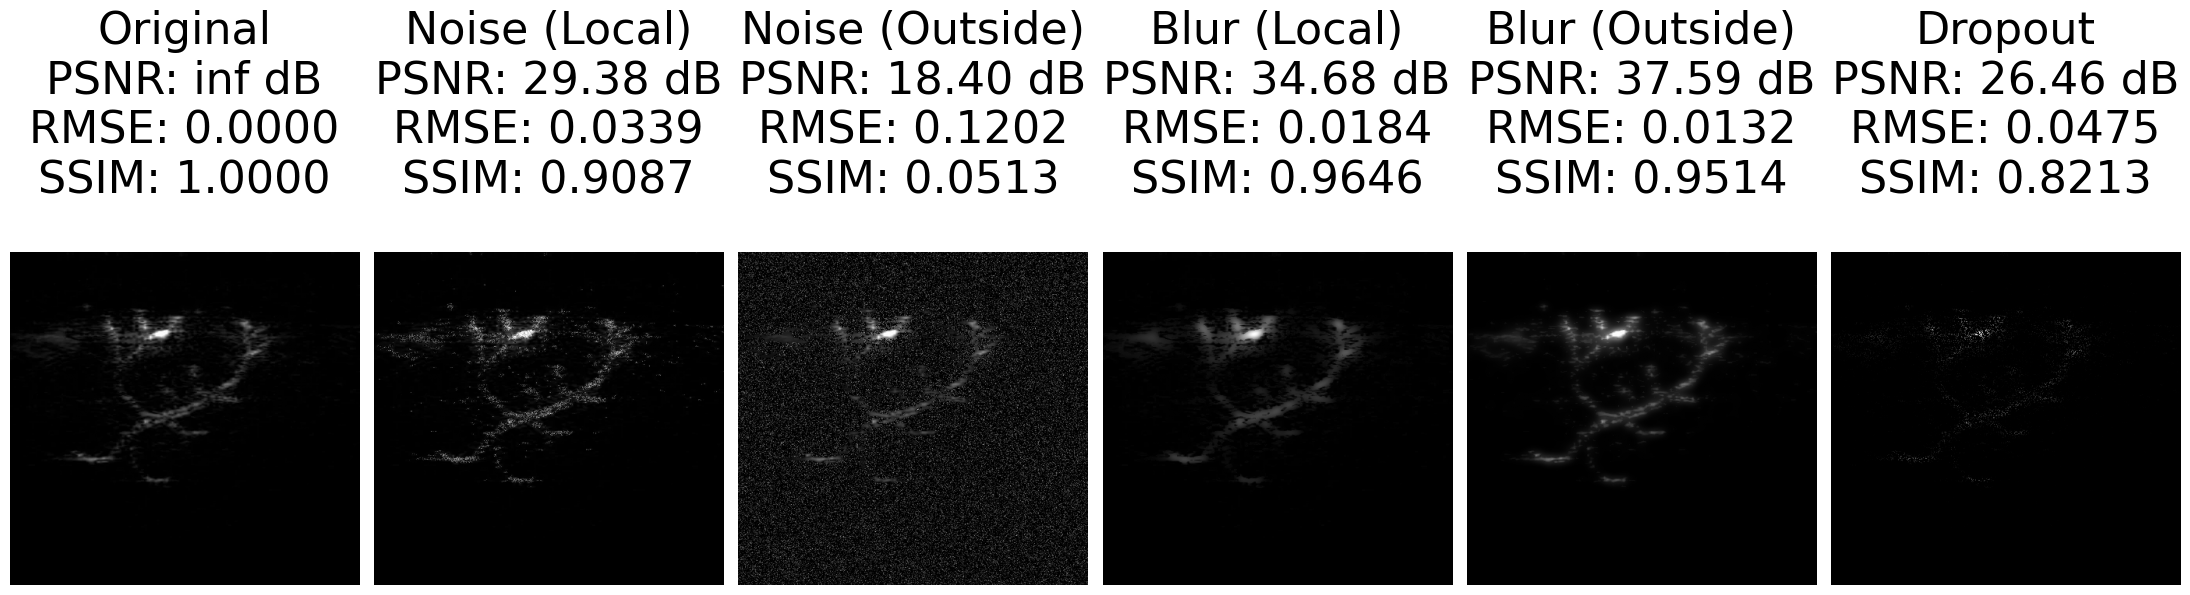

In [ ]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity,
)
from skimage.util import random_noise


def rmse(img1, img2):
    return np.sqrt(mean_squared_error(img1, img2))

def compute_metrics(original, distorted, data_range=1.0):
    return {
        'SSIM': structural_similarity(original, distorted, data_range=data_range),
        'PSNR': peak_signal_noise_ratio(original, distorted, data_range=data_range),
        'RMSE': rmse(original, distorted),
        "S3IM": s3im(original, distorted)[0],
        "MS-SSIM": msssim(original, distorted),
        "MS-S3IM": mss3im(original, distorted)[0],
        "CW-SSIM": np.average(cw_ssim(original, distorted)),
        "CW-S3IM": s3im(original, distorted, SSIM_variant=cw_ssim)[0],
        "SNR": snr_reference(original, distorted)
    }

# Image setup
with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)
noisy_img = random_noise(original_img, mode='gaussian', var=0.03, clip=True, rng=42)

mask = calculate_combined_mask(original_img, original_img)
locally_distorted_img = noisy_img * mask + original_img * (1 - mask)

outside_distorted_img = noisy_img * (1 - mask) + original_img * mask

blur_img = gaussian_filter(original_img, sigma=4)
locally_blur_img = original_img * (1 - mask) + blur_img * mask
outside_blur_img = original_img * mask + blur_img * (1 - mask)

dropped = drop_pixels(original_img, 0.8)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA3.webp") as img:
    pa_img = img.convert('L')
    pa_img = img_as_float(pa_img)

# Titles and images
titles = ["Original", "Noise (Local)", "Noise (Outside)", "Blur (Local)", "Blur (Outside)", "Dropout"]
images = [original_img, locally_distorted_img, outside_distorted_img, locally_blur_img, outside_blur_img, dropped]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(22, 6))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB
RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}
""",
fontsize=32
    )

plt.tight_layout()
plt.show()


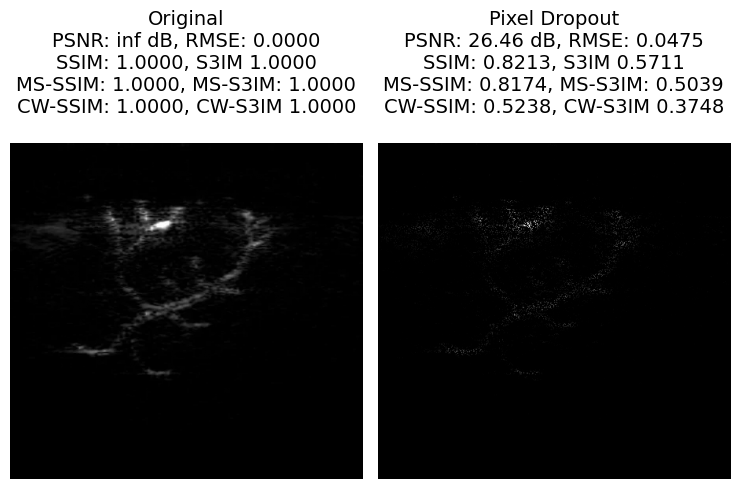

In [ ]:
titles = ["Original", "Pixel Dropout"]
images = [original_img, dropped]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(7.5, 6))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB, RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}, S3IM {metrics['S3IM']:.4f}
MS-SSIM: {metrics['MS-SSIM']:.4f}, MS-S3IM: {metrics['MS-S3IM']:.4f}
CW-SSIM: {metrics['CW-SSIM']:.4f}, CW-S3IM {metrics['CW-S3IM']:.4f}
""",
fontsize=14
    )

plt.tight_layout()
plt.show()

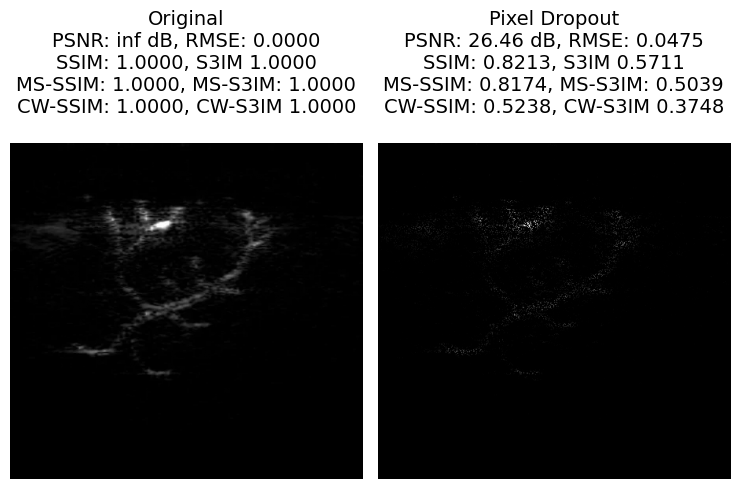

In [ ]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity
from skimage.util import random_noise


def rmse(img1, img2):
    return np.sqrt(mean_squared_error(img1, img2))

def compute_metrics(original, distorted, data_range=1.0):
    return {
        'SSIM': structural_similarity(original, distorted, data_range=data_range),
        'PSNR': peak_signal_noise_ratio(original, distorted, data_range=data_range),
        'RMSE': rmse(original, distorted),
        "S3IM": s3im(original, distorted)[0],
        "MS-SSIM": msssim(original, distorted),
        "MS-S3IM": mss3im(original, distorted)[0],
        "CW-SSIM": np.average(cw_ssim(original, distorted)),
        "CW-S3IM": s3im(original, distorted, SSIM_variant=cw_ssim)[0],
        "SNR": snr_reference(original, distorted)
    }

# Image setup
with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)
noisy_img = random_noise(original_img, mode='gaussian', var=0.03, clip=True, rng=42)

mask = calculate_combined_mask(original_img, original_img)
locally_distorted_img = noisy_img * mask + original_img * (1 - mask)

outside_distorted_img = noisy_img * (1 - mask) + original_img * mask

blur_img = gaussian_filter(original_img, sigma=4)
locally_blur_img = original_img * (1 - mask) + blur_img * mask
outside_blur_img = original_img * mask + blur_img * (1 - mask)

dropped = drop_pixels(original_img, 0.8)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA3.webp") as img:
    pa_img = img.convert('L')
    pa_img = img_as_float(pa_img)

# Titles and images
titles = ["Original", "Noise (Local)", "Noise (Outside)", "Blur (Local)", "Blur (Outside)", "Dropout"]
images = [original_img, locally_distorted_img, outside_distorted_img, locally_blur_img, outside_blur_img, dropped]

titles = ["Original", "Pixel Dropout"]
images = [original_img, dropped]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(7.5, 6))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB, RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}, S3IM {metrics['S3IM']:.4f}
MS-SSIM: {metrics['MS-SSIM']:.4f}, MS-S3IM: {metrics['MS-S3IM']:.4f}
CW-SSIM: {metrics['CW-SSIM']:.4f}, CW-S3IM {metrics['CW-S3IM']:.4f}
""",
fontsize=14
    )

plt.tight_layout()
plt.show()

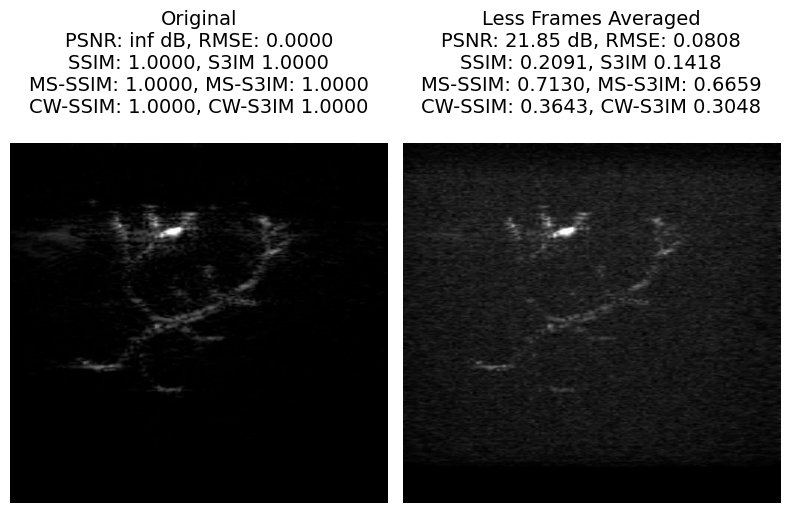

In [ ]:
titles = ["Original", "Less Frames Averaged"]
images = [original_img, pa_img]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(8, 8))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB, RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}, S3IM {metrics['S3IM']:.4f}
MS-SSIM: {metrics['MS-SSIM']:.4f}, MS-S3IM: {metrics['MS-S3IM']:.4f}
CW-SSIM: {metrics['CW-SSIM']:.4f}, CW-S3IM {metrics['CW-S3IM']:.4f}
""",
fontsize=14
    )

plt.tight_layout()
plt.show()
# PA1 - 25600
# PA2 - 128
# PA3 - 256
# PA4 - 384
# PA5 - 640
# PA6 - 1280
# PA7 - 2560

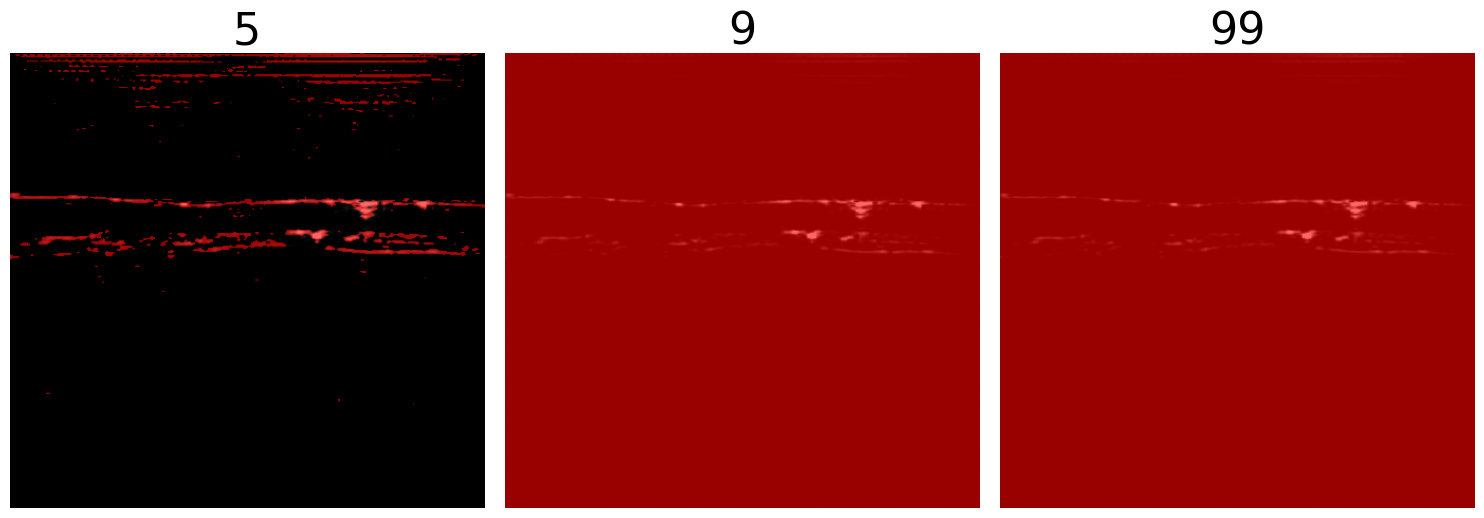

In [ ]:
mask_low = calculate_combined_mask(greyscaleImages[0], greyscaleImages[0], 0.5)
mask_mid = calculate_combined_mask(greyscaleImages[0], greyscaleImages[0], 0.90)
mask_high = calculate_combined_mask(greyscaleImages[0], greyscaleImages[0], 0.90)

masks = [mask_low, mask_mid, mask_high]
titles = ['5', '9', '99']


visualize_multiple_masks(greyscaleImages[0], masks, titles, alpha=0.6)

Excluded image indices: [5 4]
Excluded sparsities: [0.64482557 0.64575571]


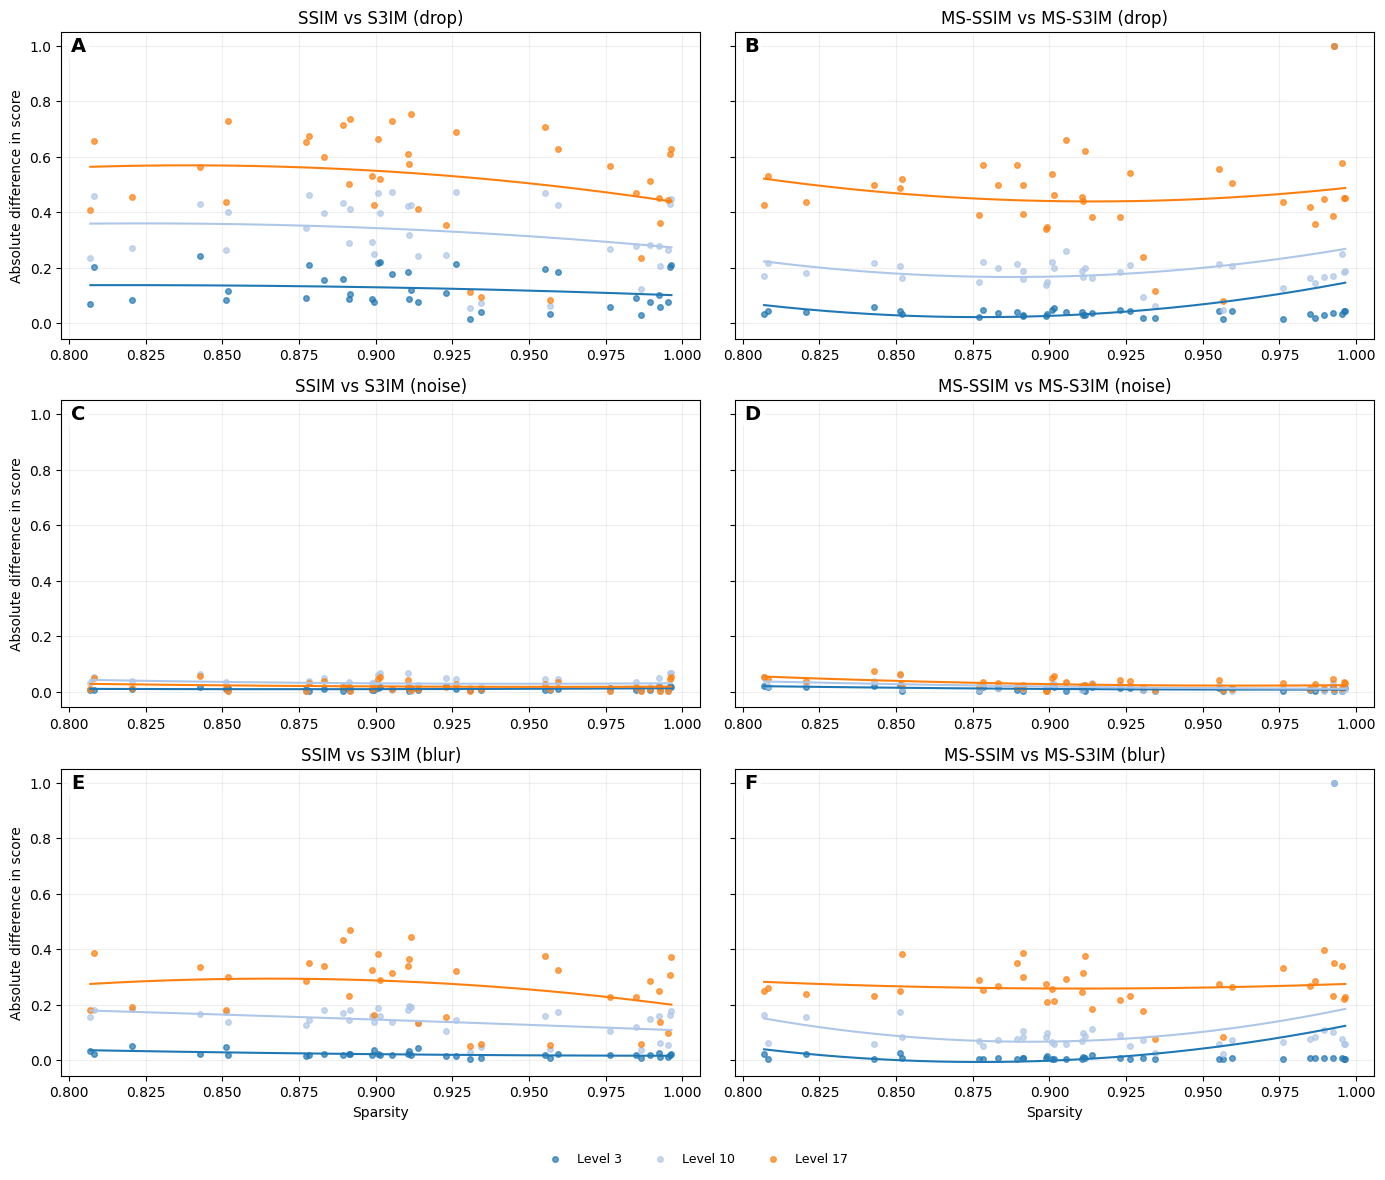

In [ ]:

# ============================================================
# Calculate sparsity
# ============================================================

sparsities2 = np.asarray(
    [
        1 - calculate_single_mask(x).mean()
        for x in greyscaleImages
    ],
    dtype=float,
)


# ============================================================
# Exclude the two least-sparse images
# ============================================================

exclude_indices = np.argsort(
    sparsities2
)[:2]

print(
    "Excluded image indices:",
    exclude_indices,
)

print(
    "Excluded sparsities:",
    sparsities2[exclude_indices],
)


# ============================================================
# Compute differences
# ============================================================

diffs_drop = compute_differences(
    scores_drop,
    sparsities2,
    exclude_indices=exclude_indices,
    level_step=7,
    level_start=3,
)

diffs_noise = compute_differences(
    scores_noise,
    sparsities2,
    exclude_indices=exclude_indices,
    level_step=7,
    level_start=3,
)

diffs_blur = compute_differences(
    scores_blur,
    sparsities2,
    exclude_indices=exclude_indices,
    level_step=7,
    level_start=3,
)


# ============================================================
# Plot
# ============================================================

plot_all_six(
    diffs_drop,
    diffs_noise,
    diffs_blur,
    poly_deg=2,
)



c:\Users\SemKj\Downloads\s3im\ssim\util\utils.py:664: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(left=0.02, right=0.98, top=0.96, bottom=0.22)


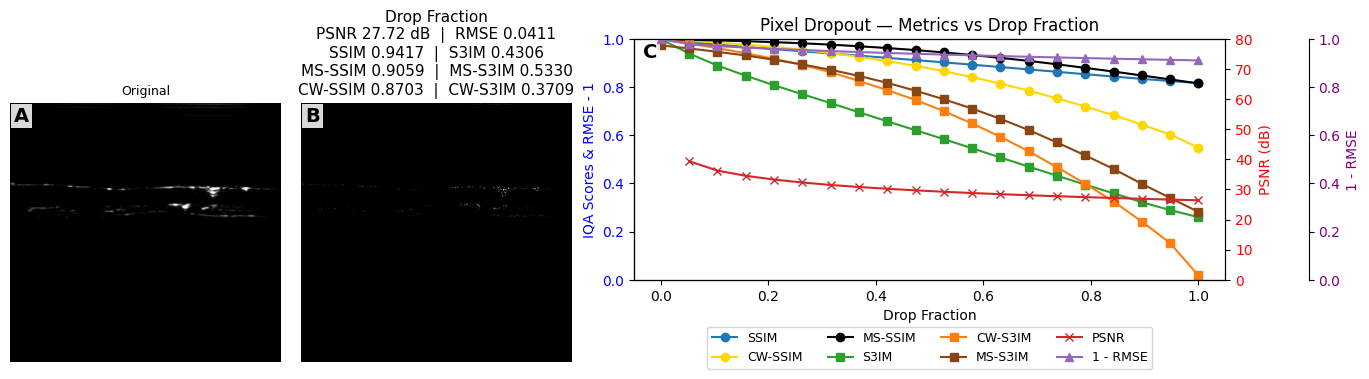

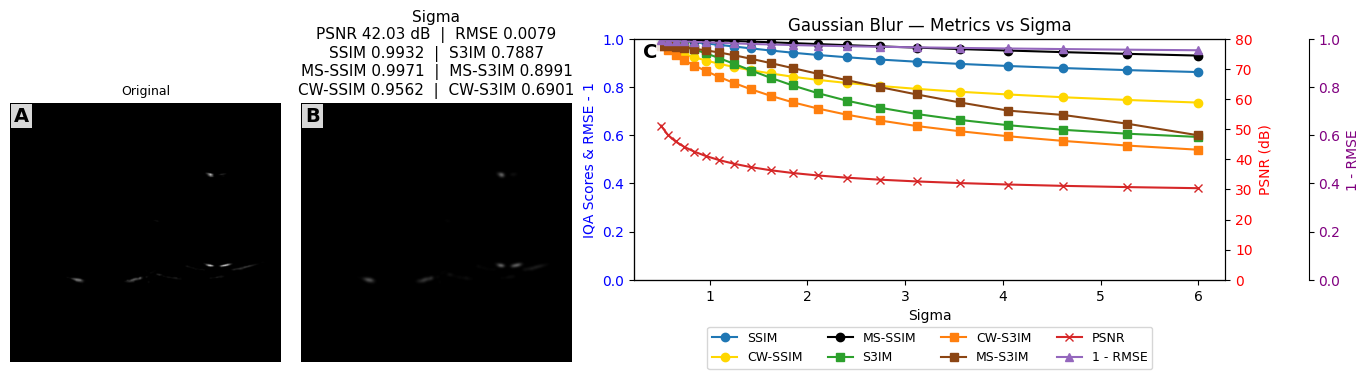

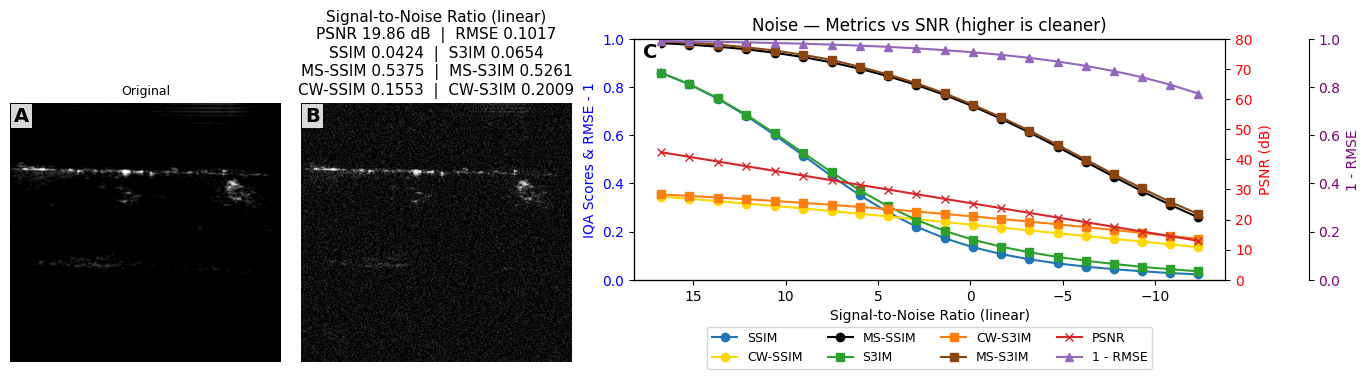

c:\Users\SemKj\Downloads\s3im\ssim\util\utils.py:664: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(left=0.02, right=0.98, top=0.96, bottom=0.22)


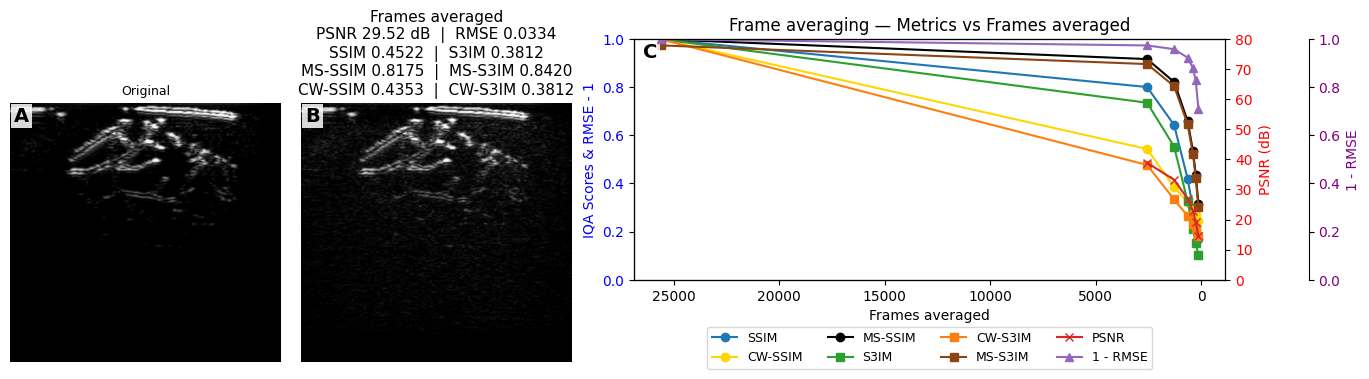

{'ssim': [1.0,
  0.8012043327396277,
  0.6435588693205058,
  0.4203435365865003,
  0.29558984429698404,
  0.22475097110305753,
  0.16841987753152546],
 'wssim': [1.0,
  0.5434562433105726,
  0.38599571336362637,
  0.3213279244134535,
  0.2945279870057991,
  0.27074729710856277,
  0.2457296853871417],
 'msssim': [1.0,
  0.917507243462098,
  0.8222423837735102,
  0.6601072993033972,
  0.5335972003447704,
  0.4365598817284291,
  0.31586381687949866],
 's3im': [1.0,
  0.7359236738598529,
  0.5536647048325912,
  0.3257668736878845,
  0.21257256513655748,
  0.15121031355680384,
  0.1029392606992985],
 'mss3im': [0.9743589758872986,
  0.896757960319519,
  0.8048166036605835,
  0.6466342806816101,
  0.5218154191970825,
  0.4246814548969269,
  0.3028615415096283],
 'ws3im': [1.0,
  0.47699892841905583,
  0.3337041271449988,
  0.26535813603181313,
  0.23342617259571755,
  0.20977466278402596,
  0.1823663201418373],
 'mse': [0.0,
  0.0006637750483359479,
  0.0017089052035440548,
  0.0058540386869

In [ ]:
from scipy.ndimage import gaussian_filter
from skimage.util import random_noise

# Keep letters continuous across figures
next_lab = 'A'

original_img = greyscaleImages[0]
dropped = drop_pixels(original_img, 0.8)

# --- Dropout ---
plot_single_row_match_image_height(
    original_img=original_img,
    distorted_img=dropped,
    x_levels=drop_fractions,
    avg_scores=avg_scores_drop,
    xlabel="Drop Fraction",
    title_curves="Pixel Dropout — Metrics vs Drop Fraction",
    compute_metrics_fn=compute_metrics,
    width_ratio=(2.7, 2.8),
    invert_x=False,
    start_label= 'A'
)

# --- Blur ---
og_img = greyscaleImages[20]
blurred_img = gaussian_filter(og_img, sigma=2)

plot_single_row_match_image_height(
    original_img=og_img,
    distorted_img=blurred_img,
    x_levels=blur_levels,
    avg_scores=avg_scores_blur,
    xlabel="Sigma",
    title_curves="Gaussian Blur — Metrics vs Sigma",
    compute_metrics_fn=compute_metrics,
    width_ratio=(2.7, 2.8),
    invert_x=False,
    start_label= 'A'
)

# --- Noise ---
og_img2 = greyscaleImages[26]
noisy_img = random_noise(og_img2, mode='gaussian', var=0.02, clip=True, rng=42)

plot_single_row_match_image_height(
    original_img=og_img2,
    distorted_img=noisy_img,
    x_levels=avg_scores_noise['snr'],
    avg_scores=avg_scores_noise,
    xlabel="Signal-to-Noise Ratio (linear)",
    title_curves="Noise — Metrics vs SNR (higher is cleaner)",
    compute_metrics_fn=compute_metrics,
    width_ratio=(2.7, 2.8),
    invert_x=True,
    start_label= 'A'
)


x_levels = [25600, 2560, 1280, 640, 384, 256, 128]

df_pa = df[df["distortion_type"] == "pa"].copy()

# Desired order:
# clean first (25600), then reverse the remaining levels
desired_order = [x_levels[0]] + x_levels[1:][::-1]

df_pa["distortion_level"] = pd.Categorical(
    df_pa["distortion_level"],
    categories=desired_order,
    ordered=True,
)

df_pa = df_pa.sort_values("distortion_level")

avg_pas = {
    metric: group["avg_score"].tolist()
    for metric, group in df_pa.groupby(
        "metric_variant",
        sort=False,
        observed=True,
    )
}


im = PA_from_base['Phantoms__PrintedPhantom_Rf_062323_234747']['PA1']
im2 = PA_from_base['Phantoms__PrintedPhantom_Rf_062323_234747']['PA4']
plot_single_row_match_image_height(
    original_img=im,
    distorted_img=im2,
    x_levels=x_levels,
    avg_scores=avg_pas,
    xlabel="Frames averaged",
    title_curves="Frame averaging — Metrics vs Frames averaged",
    compute_metrics_fn=compute_metrics,
    width_ratio=(2.7, 2.8),
    invert_x=True,
    start_label= 'A'
)
avg_pas

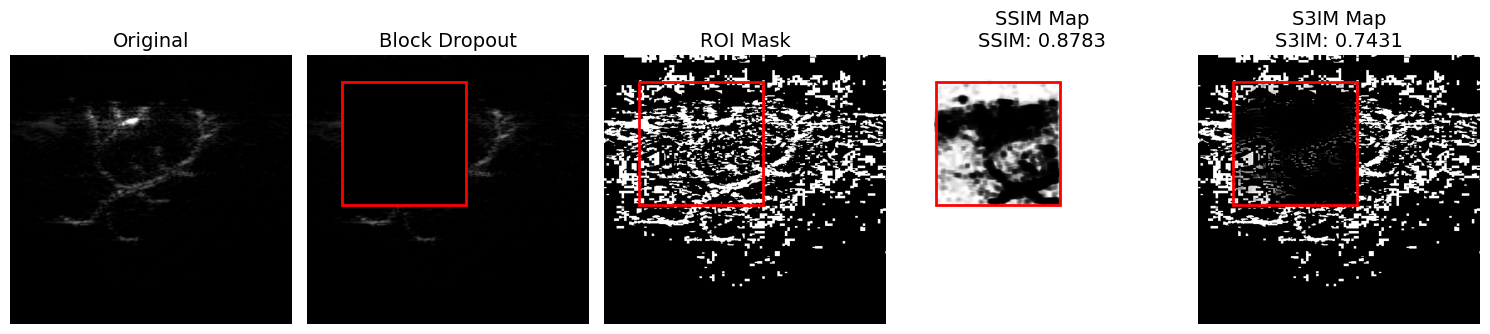

In [ ]:
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)

# Apply dropout
block_dropped_mask = calculate_single_mask(original_img)
block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(original_img, block_dropped_img, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(original_img, block_dropped_img, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "ROI Mask", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    original_img, 
    block_dropped_img, 
    s3im_mask,
    ssim_map, 
    s3im_map
]

from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)

# Apply dropout
block_dropped_mask = calculate_single_mask(original_img)
block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(original_img, block_dropped_img, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(original_img, block_dropped_img, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "ROI Mask", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    original_img, 
    block_dropped_img, 
    s3im_mask,
    ssim_map, 
    s3im_map
]

# Plot in 2 rows (3 cols max)
fig, axes = plt.subplots(1, 5, figsize=(15, 8))
axes = axes.flatten()

for idx, (ax, title, img) in enumerate(zip(axes, titles, images)):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
    if idx != 0:
        rect = Rectangle((x, y), size, size, linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
    if idx == 3:
        ax.set_title(
            f"""{title}
SSIM: {SSIM_score:.4f}""",
            fontsize=14
        )
    elif title == "S3IM Map":
        ax.set_title(
            f"""{title}
S3IM: {S3IM_score:.4f}""",
            fontsize=14
        )
    else:
        ax.set_title(title, fontsize=14)

# Hide any extra subplot (if 6th is unused)
if len(images) < len(axes):
    for i in range(len(images), len(axes)):
        axes[i].axis("off")

plt.tight_layout()
plt.show()

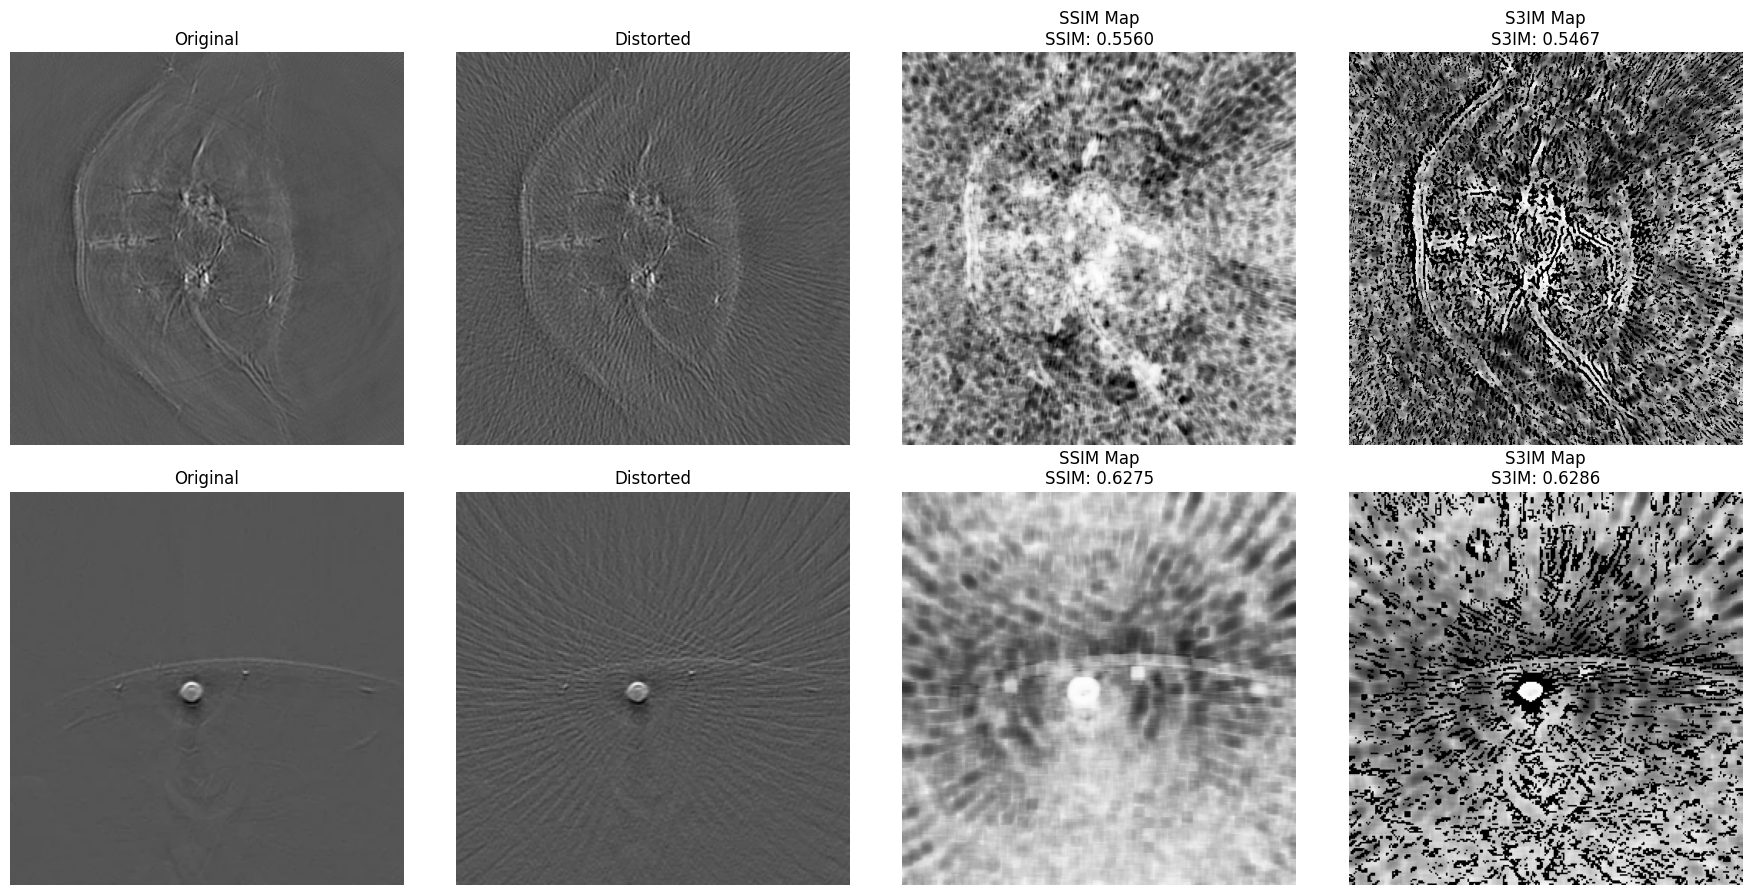

In [ ]:
from matplotlib import pyplot as plt
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)

# Apply dropout
block_dropped_mask = calculate_single_mask(original_img)
block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(original_img, block_dropped_img, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(original_img, block_dropped_img, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "ROI Mask", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    original_img, 
    block_dropped_img, 
    s3im_mask,
    ssim_map, 
    s3im_map
]

from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_2213/image_192_full.webp") as img:
    ref_img = img.convert('L')
    ref_img = img_as_float(ref_img)
    # mask2 = calculate_single_mask(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_2213/image_192_128.webp") as img:
    ref_img2 = img.convert('L')
    ref_img2 = img_as_float(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_3215/SWFD_semicircle_sc_BP_slice0046.webp") as img:
    ref_img3 = img.convert('L')
    ref_img3 = img_as_float(ref_img3)
    # mask2 = calculate_single_mask(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_3215/SWFD_semicircle_sc,ss32_BP_slice0046.webp") as img:
    ref_img4 = img.convert('L')
    ref_img4 = img_as_float(ref_img4)
# Apply dropout
# block_dropped_mask = calculate_single_mask(original_img)
# block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(ref_img, ref_img2, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(ref_img, ref_img2, window_size=7)

SSIM_score2, ssim_map2 = structural_similarity(ref_img3, ref_img4, win_size=7, full=True, data_range=1.0)
S3IM_score2, s3im_mask2, s3im_map2 = s3im(ref_img3, ref_img4, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    ref_img,
    ref_img2, 
    ssim_map, 
    s3im_map
]

# Titles for both sets
titles = ["Original", "Distorted", "SSIM Map", "S3IM Map"]

# First comparison
images1 = [ref_img, ref_img2, ssim_map, s3im_map]
scores1 = [None, None, SSIM_score, S3IM_score]

# Second comparison
images2 = [ref_img3, ref_img4, ssim_map2, s3im_map2]
scores2 = [None, None, SSIM_score2, S3IM_score2]

# Create subplot grid: 2 rows × 4 cols
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# Plot first row
for idx, (ax, title, img, score) in enumerate(zip(axes[0], titles, images1, scores1)):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
    if score is not None:
        ax.set_title(f"{title}\n{title.split()[0]}: {score:.4f}", fontsize=12)
    else:
        ax.set_title(title, fontsize=12)

# Plot second row
for idx, (ax, title, img, score) in enumerate(zip(axes[1], titles, images2, scores2)):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
    if score is not None:
        ax.set_title(f"{title}\n{title.split()[0]}: {score:.4f}", fontsize=12)
    else:
        ax.set_title(title, fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# def plot_pixel_drop_from_df(df_drop, poly_deg=2):
#     """
#     Plot Pixel Dropout results directly from df_drop.

#     Expected columns:
#         distortion_type
#         reference_image_idx
#         distortion_level
#         level_idx
#         metric_variant
#         score
#         sparsity

#     Creates:
#         A: SSIM vs S3IM
#         B: MS-SSIM vs MS-S3IM

#     Each point = one reference image at one dropout level.
#     Legend = actual dropout fraction.
#     """

#     # --------------------------------------------------------
#     # Copy + clean
#     # --------------------------------------------------------

#     df = df_drop.copy()

#     df["score"] = pd.to_numeric(
#         df["score"],
#         errors="coerce",
#     )

#     df["sparsity"] = pd.to_numeric(
#         df["sparsity"],
#         errors="coerce",
#     )

#     df["distortion_level"] = pd.to_numeric(
#         df["distortion_level"],
#         errors="coerce",
#     )

#     # Only dropout
#     df = df[
#         df["distortion_type"] == "drop"
#     ].copy()

#     # --------------------------------------------------------
#     # Helper to extract a metric
#     # --------------------------------------------------------

#     def get_metric(metric_name):
#         return df[
#             df["metric_variant"] == metric_name
#         ][
#             [
#                 "reference_image_idx",
#                 "distortion_level",
#                 "score",
#                 "sparsity",
#             ]
#         ].copy()

#     # --------------------------------------------------------
#     # Get metrics
#     # --------------------------------------------------------

#     ssim_df = get_metric("ssim").rename(
#         columns={
#             "score": "ssim_score",
#             "sparsity": "sparsity",
#         }
#     )

#     s3im_df = get_metric("s3im").rename(
#         columns={
#             "score": "s3im_score",
#         }
#     )[
#         [
#             "reference_image_idx",
#             "distortion_level",
#             "s3im_score",
#         ]
#     ]

#     msssim_df = get_metric("msssim").rename(
#         columns={
#             "score": "msssim_score",
#             "sparsity": "sparsity",
#         }
#     )

#     mss3im_df = get_metric("mss3im").rename(
#         columns={
#             "score": "mss3im_score",
#         }
#     )[
#         [
#             "reference_image_idx",
#             "distortion_level",
#             "mss3im_score",
#         ]
#     ]

#     # --------------------------------------------------------
#     # SSIM vs S3IM
#     # --------------------------------------------------------

#     ssim_pair = ssim_df.merge(
#         s3im_df,
#         on=[
#             "reference_image_idx",
#             "distortion_level",
#         ],
#         how="inner",
#     )

#     ssim_pair["diff"] = np.abs(
#         ssim_pair["ssim_score"]
#         - ssim_pair["s3im_score"]
#     )

#     # --------------------------------------------------------
#     # MS-SSIM vs MS-S3IM
#     # --------------------------------------------------------

#     msssim_pair = msssim_df.merge(
#         mss3im_df,
#         on=[
#             "reference_image_idx",
#             "distortion_level",
#         ],
#         how="inner",
#     )

#     msssim_pair["diff"] = np.abs(
#         msssim_pair["msssim_score"]
#         - msssim_pair["mss3im_score"]
#     )

#     # --------------------------------------------------------
#     # Levels
#     # --------------------------------------------------------

#     all_levels = sorted(
#         df["distortion_level"]
#         .dropna()
#         .unique()
#     )

#     color_map = _level_color_map(
#         all_levels
#     )

#     # --------------------------------------------------------
#     # Figure
#     # --------------------------------------------------------

#     fig, axes = plt.subplots(
#         1,
#         2,
#         figsize=(14, 5),
#         sharey=True,
#     )

#     panel_labels = ["A", "B"]

#     legend_handles = {}

#     # ========================================================
#     # PANEL A — SSIM vs S3IM
#     # ========================================================

#     ax = axes[0]

#     for level in all_levels:

#         data = ssim_pair[
#             ssim_pair["distortion_level"] == level
#         ].copy()

#         if data.empty:
#             continue

#         x = data["sparsity"].to_numpy(
#             dtype=float
#         )

#         y = data["diff"].to_numpy(
#             dtype=float
#         )

#         valid = (
#             np.isfinite(x)
#             & np.isfinite(y)
#         )

#         x = x[valid]
#         y = y[valid]

#         if len(x) == 0:
#             continue

#         label = f"{float(level):.2f}"

#         sc = ax.scatter(
#             x,
#             y,
#             s=16,
#             alpha=0.7,
#             color=color_map[level],
#             label=label,
#         )

#         if level not in legend_handles:
#             legend_handles[level] = sc

#         # Polynomial fit
#         if (
#             np.unique(x).size >= poly_deg + 1
#         ):
#             coeffs = np.polyfit(
#                 x,
#                 y,
#                 deg=poly_deg,
#             )

#             xs = np.linspace(
#                 x.min(),
#                 x.max(),
#                 300,
#             )

#             ax.plot(
#                 xs,
#                 np.polyval(
#                     coeffs,
#                     xs,
#                 ),
#                 linewidth=1.5,
#                 color=color_map[level],
#             )

#     ax.set_title(
#         "SSIM vs S3IM (drop)"
#     )

#     ax.set_xlabel(
#         "Sparsity"
#     )

#     ax.set_ylabel(
#         "Absolute difference in score"
#     )

#     ax.grid(
#         True,
#         alpha=0.2,
#     )

#     _panel_tag(
#         ax,
#         "A",
#     )

#     # ========================================================
#     # PANEL B — MS-SSIM vs MS-S3IM
#     # ========================================================

#     ax = axes[1]

#     for level in all_levels:

#         data = msssim_pair[
#             msssim_pair["distortion_level"] == level
#         ].copy()

#         if data.empty:
#             continue

#         x = data["sparsity"].to_numpy(
#             dtype=float
#         )

#         y = data["diff"].to_numpy(
#             dtype=float
#         )

#         valid = (
#             np.isfinite(x)
#             & np.isfinite(y)
#         )

#         x = x[valid]
#         y = y[valid]

#         if len(x) == 0:
#             continue

#         label = f"{float(level):.2f}"

#         sc = ax.scatter(
#             x,
#             y,
#             s=16,
#             alpha=0.7,
#             color=color_map[level],
#             label=label,
#         )

#         # Polynomial fit
#         if (
#             np.unique(x).size >= poly_deg + 1
#         ):
#             coeffs = np.polyfit(
#                 x,
#                 y,
#                 deg=poly_deg,
#             )

#             xs = np.linspace(
#                 x.min(),
#                 x.max(),
#                 300,
#             )

#             ax.plot(
#                 xs,
#                 np.polyval(
#                     coeffs,
#                     xs,
#                 ),
#                 linewidth=1.5,
#                 color=color_map[level],
#             )

#     ax.set_title(
#         "MS-SSIM vs MS-S3IM (drop)"
#     )

#     ax.set_xlabel(
#         "Sparsity"
#     )

#     ax.grid(
#         True,
#         alpha=0.2,
#     )

#     _panel_tag(
#         ax,
#         "B",
#     )

#     # ========================================================
#     # Shared legend
#     # ========================================================

#     legend_order = sorted(
#         legend_handles.keys()
#     )

#     if legend_order:

#         fig.legend(
#             [
#                 legend_handles[level]
#                 for level in legend_order
#             ],
#             [
#                 f"{float(level):.2f}"
#                 for level in legend_order
#             ],
#             title="Drop fraction",
#             loc="lower center",
#             ncol=min(
#                 8,
#                 len(legend_order),
#             ),
#             bbox_to_anchor=(0.5, 0.02),
#             frameon=False,
#             fontsize=9,
#         )

#     plt.tight_layout(
#         rect=[
#             0,
#             0.07,
#             1,
#             1,
#         ]
#     )

#     plt.show()


# plot_pixel_drop_from_df(
#     df_drop,
#     poly_deg=2,
# )
# df_drop.dtypes